# W5 Tutorial — Data Cleaning & QA/QC
**EN524R / CE801V · Module 2 · Week 5**

**Goal:** Continue the existing W2–W4 GitHub project and document a scientifically defensible QA/QC workflow.

**Workflow:** Profile → Flag → Diagnose → Decide → Compare → Audit → Export → Commit

**Teacher demo:** `data/sample/zhongli_aq_2025.csv`. **Student PBL:** adapt the input, variable(s), and QC rules to Assignment 3–4.

> **Outlier ≠ Error.** Investigate unusual observations before excluding them.

## Step 0 — Setup / locate the project
Save this notebook as `notebooks/04_qaqc.ipynb` in the **existing** repository. The default uses the W2 teaching sample to reproduce the W5 lecture examples. Set `USE_W4_PROCESSED=True` and edit the filename to use your W4 output. Do not overwrite original data.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

USE_W4_PROCESSED = True
W4_PROCESSED_NAME = "zhongli_hourly_processed.csv"
VALUE_COL = "PM2.5"  # For your PBL, change the variable and corresponding rules.

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data/sample/zhongli_aq_2025.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("W2 sample not found. Place notebook under the existing project/notebooks/ folder.")
INPUT_FILE = (PROJECT_ROOT / "data/processed" / W4_PROCESSED_NAME if USE_W4_PROCESSED
              else PROJECT_ROOT / "data/sample/zhongli_aq_2025.csv")
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"Missing input: {INPUT_FILE}")
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
FIGURES_DIR = PROJECT_ROOT / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_ROOT)
print("Input:", INPUT_FILE)

Project: /Users/sheng-po/Library/CloudStorage/Dropbox/20231204_中原環工/05_課程/115-1_環境數據分析/01_PPT/materials_for_W5/EN524R_W2_GitHub_Demo
Input: /Users/sheng-po/Library/CloudStorage/Dropbox/20231204_中原環工/05_課程/115-1_環境數據分析/01_PPT/materials_for_W5/EN524R_W2_GitHub_Demo/data/processed/zhongli_hourly_processed.csv


## Step 1 — Profile: inspect before changing anything
What does one row represent? Check missingness, dtype, duplicates, negative/sentinel values, and extreme observations. The teaching CSV also has a negative O₃ value; rules must be **variable-specific**.

In [6]:
df = pd.read_csv(INPUT_FILE)
required = {"datetime", VALUE_COL}
if not required.issubset(df.columns):
    raise KeyError(f"Missing columns: {sorted(required - set(df.columns))}")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("n_missing"))

x = df.copy()
x["datetime"] = pd.to_datetime(x["datetime"], errors="coerce")
x[VALUE_COL] = pd.to_numeric(x[VALUE_COL], errors="coerce")
keys = ["station", "datetime"] if "station" in x.columns else ["datetime"]

n_rows = len(x)
n_missing = int(x[VALUE_COL].isna().sum())
n_negative = int(x[VALUE_COL].lt(0).sum())
n_185 = int(x[VALUE_COL].eq(185).sum())
n_duplicates = int(x.duplicated(keys).sum())
n_bad_time = int(x["datetime"].isna().sum())
print(f"Rows={n_rows}; missing={n_missing}; negative={n_negative}; 185={n_185}")
print(f"Duplicate keys={n_duplicates}; invalid timestamps={n_bad_time}")
if "O3" in x:
    print("Additional diagnostic: negative O3 values =",
          int(pd.to_numeric(x["O3"], errors="coerce").lt(0).sum()))

Shape: (168, 6)
Columns: ['datetime', 'station', 'PM2.5', 'O3', 'WS', 'PM2.5_valid']


,datetime,station,PM2.5,O3,WS,PM2.5_valid
0,2025-01-01 00:00:00,Zhongli,14.3,24.8,1.6,14.3
1,2025-01-01 01:00:00,Zhongli,13.3,25.9,3.6,13.3
2,2025-01-01 02:00:00,Zhongli,9.1,15.4,1.2,9.1
3,2025-01-01 03:00:00,Zhongli,14.0,18.9,1.0,14.0
4,2025-01-01 04:00:00,Zhongli,13.9,6.6,1.4,13.9


,dtype
datetime,object
station,object
PM2.5,float64
O3,float64
WS,float64
PM2.5_valid,float64


,n_missing
datetime,0
station,0
PM2.5,1
O3,0
WS,0
PM2.5_valid,3


Rows=168; missing=1; negative=2; 185=1
Duplicate keys=0; invalid timestamps=0
Additional diagnostic: negative O3 values = 1


## Step 2 — Flag and decide (do not silently delete)
**Teaching rule:** negative PM₂.₅ is invalid and masked to `NaN` in a **new** variable. The high value `185` is flagged but **retained** pending investigation. `NaN` is not automatically imputed. Other datasets require provider metadata and appropriate scientific rules.

In [9]:
x["PM2.5_qc"] = x[VALUE_COL].copy()
x["flag_negative"] = x[VALUE_COL].lt(0)
x["flag_high_185"] = x[VALUE_COL].eq(185)  # illustrative investigation flag, NOT a regulatory threshold
x["flag_missing"] = x[VALUE_COL].isna()
x["flag_duplicate_key"] = x.duplicated(keys, keep=False)
x.loc[x["flag_negative"], "PM2.5_qc"] = np.nan

qc_rules = pd.DataFrame([
    {"Rule": "Originally missing", "Affected": n_missing, "Decision": "Keep missing"},
    {"Rule": "PM2.5 < 0", "Affected": n_negative, "Decision": "Mask QC copy; preserve raw"},
    {"Rule": "PM2.5 == 185 (illustrative flag)", "Affected": n_185, "Decision": "Retain; investigate"},
    {"Rule": "Duplicate station-time key", "Affected": n_duplicates, "Decision": "Inspect; do not auto-drop"},
])
display(qc_rules)
display(x.loc[x["flag_negative"] | x["flag_high_185"],
              [v for v in ["datetime", "station", VALUE_COL, "PM2.5_qc"] if v in x.columns]])

,Rule,Affected,Decision
0,Originally missing,1,Keep missing
1,PM2.5 < 0,2,Mask QC copy; preserve raw
2,PM2.5 == 185 (illustrative flag),1,Retain; investigate
3,Duplicate station-time key,0,Inspect; do not auto-drop


,datetime,station,PM2.5,PM2.5_qc
18,2025-01-01 18:00:00,Zhongli,-9999.0,NaN
57,2025-01-03 09:00:00,Zhongli,-2.0,NaN
133,2025-01-06 13:00:00,Zhongli,185.0,185.0


## Step 3 — Diagnose high observations with context
For a high value, inspect neighboring hours, nearby stations, meteorology, instrument flags, and known events. The following time window alone **cannot prove** validity.

In [12]:
cols = [v for v in ["datetime", "station", VALUE_COL, "PM2.5_qc", "WS", "RH", "TEMP"] if v in x]
if not x["flag_high_185"].any():
    print("No value equal to 185. Define an appropriate candidate flag for your own variable.")
for idx in x.index[x["flag_high_185"]]:
    t = x.loc[idx, "datetime"]
    same_station = x["station"].eq(x.loc[idx, "station"]) if "station" in x else pd.Series(True, index=x.index)
    window = same_station & x["datetime"].between(t - pd.Timedelta(hours=3), t + pd.Timedelta(hours=3))
    print("Candidate observation at", t)
    display(x.loc[window, cols].sort_values("datetime"))

Candidate observation at 2025-01-06 13:00:00


,datetime,station,PM2.5,PM2.5_qc,WS
130,2025-01-06 10:00:00,Zhongli,27.8,27.8,1.6
131,2025-01-06 11:00:00,Zhongli,22.3,22.3,1.9
132,2025-01-06 12:00:00,Zhongli,34.3,34.3,1.2
133,2025-01-06 13:00:00,Zhongli,185.0,185.0,1.5
134,2025-01-06 14:00:00,Zhongli,39.2,39.2,1.8
135,2025-01-06 15:00:00,Zhongli,33.5,33.5,0.9
136,2025-01-06 16:00:00,Zhongli,27.4,27.4,1.8


## Step 4 — Before/after plots and missingness
Raw sentinel values can compress the y-axis. Use **separate panels** for raw and screened values so the QC comparison is readable.

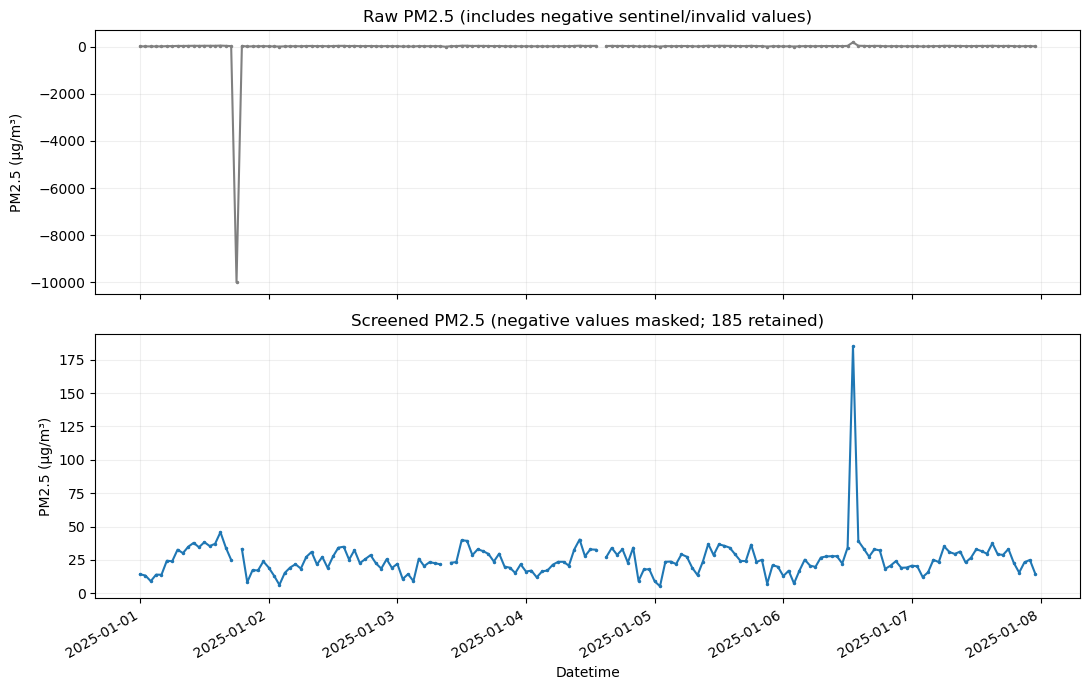

Saved: /Users/sheng-po/Library/CloudStorage/Dropbox/20231204_中原環工/05_課程/115-1_環境數據分析/01_PPT/materials_for_W5/EN524R_W2_GitHub_Demo/figures/w5_pm25_raw_vs_screened.png


In [15]:
ordered = x.sort_values("datetime")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(ordered["datetime"], ordered[VALUE_COL], color="gray", marker=".", markersize=3)
axes[0].set_title("Raw PM2.5 (includes negative sentinel/invalid values)")
axes[1].plot(ordered["datetime"], ordered["PM2.5_qc"], color="tab:blue", marker=".", markersize=3)
axes[1].set_title("Screened PM2.5 (negative values masked; 185 retained)")
for ax in axes:
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.grid(alpha=0.2)
axes[1].set_xlabel("Datetime")
fig.autofmt_xdate()
fig.tight_layout()
plot_file = FIGURES_DIR / "w5_pm25_raw_vs_screened.png"
fig.savefig(plot_file, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", plot_file)

,missing_or_screened
datetime,
2025-01-01,1
2025-01-02,0
2025-01-03,1
2025-01-04,1
2025-01-05,0
2025-01-06,0
2025-01-07,0


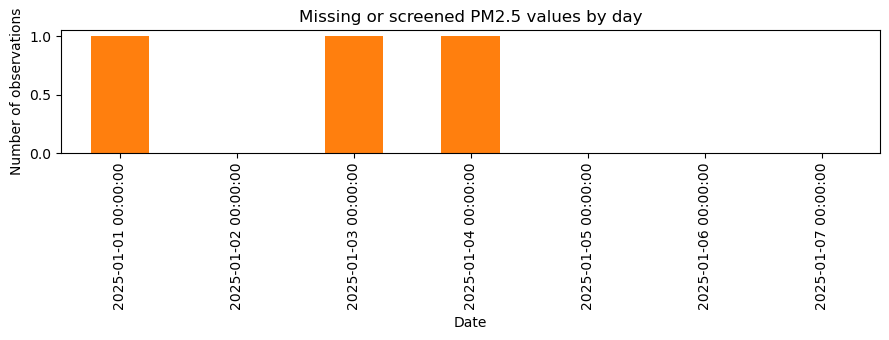

In [17]:
missing_daily = (x.dropna(subset=["datetime"])
                 .set_index("datetime")["PM2.5_qc"]
                 .isna().resample("D").sum())
display(missing_daily.rename("missing_or_screened").to_frame())
fig, ax = plt.subplots(figsize=(9, 3.5))
missing_daily.plot.bar(ax=ax, color="tab:orange")
ax.set_title("Missing or screened PM2.5 values by day")
ax.set_ylabel("Number of observations")
ax.set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "w5_pm25_missing_by_day.png", dpi=160, bbox_inches="tight")
plt.show()

## Step 5 — Sensitivity analysis: test a defensible alternative
Compare (1) raw values (invalid; for diagnosis only), (2) negative values screened with 185 retained, and (3) hypothetical exclusion of 185. **Scenario 3 is NOT an automatic deletion rule.**

In [19]:
raw = x[VALUE_COL]
screened = x["PM2.5_qc"]
without_185 = screened.where(~x["flag_high_185"])
sensitivity = pd.DataFrame([
    {"Scenario": "Raw (includes invalid codes)", "N_valid": int(raw.count()),
     "Mean": raw.mean(), "Median": raw.median()},
    {"Scenario": "Negative values screened; 185 retained", "N_valid": int(screened.count()),
     "Mean": screened.mean(), "Median": screened.median()},
    {"Scenario": "Hypothetical: also exclude 185", "N_valid": int(without_185.count()),
     "Mean": without_185.mean(), "Median": without_185.median()},
])
display(sensitivity.round(2))
print("Change in mean (hypothetical - default):", round(without_185.mean() - screened.mean(), 3))

,Scenario,N_valid,Mean,Median
0,Raw (includes invalid codes),167,-34.74,23.80
1,Negative values screened; 185 retained,165,25.45,23.90
2,Hypothetical: also exclude 185,164,24.48,23.85


Change in mean (hypothetical - default): -0.973


## Step 6 — QA/QC audit table
**Row count is not valid-value count.** Masking two values does not delete two rows. Record the rationale and affected counts.

In [22]:
audit = pd.DataFrame([
    {"Step": "Raw load", "Rows": n_rows, "Valid_PM25": int(raw.count()),
     "Notes": f"{n_missing} originally missing"},
    {"Step": "Parse datetime", "Rows": len(x), "Valid_PM25": int(raw.count()),
     "Notes": f"{n_bad_time} unparseable timestamps"},
    {"Step": "Screen negative PM2.5", "Rows": len(x), "Valid_PM25": int(screened.count()),
     "Notes": f"{n_negative} negative values masked to NaN"},
    {"Step": "Flag 185 for investigation", "Rows": len(x), "Valid_PM25": int(screened.count()),
     "Notes": f"{n_185} flagged; retained in default QC data"},
])
display(audit)

,Step,Rows,Valid_PM25,Notes
0,Raw load,168,167,1 originally missing
1,Parse datetime,168,167,0 unparseable timestamps
2,Screen negative PM2.5,168,165,2 negative values masked to NaN
3,Flag 185 for investigation,168,165,1 flagged; retained in default QC data


## Step 7 — Export processed results and figures
Keep the source CSV intact. Save QA/QC outputs under `data/processed/`, figures under `figures/`, and keep the notebook under `notebooks/`. **Do not commit API keys or restricted/large raw data.**

In [25]:
outputs = {
    "w5_qaqc_hourly.csv": x,
    "w5_qaqc_rules.csv": qc_rules,
    "w5_qaqc_audit.csv": audit,
    "w5_qaqc_sensitivity.csv": sensitivity,
}
for filename, table in outputs.items():
    path = PROCESSED_DIR / filename
    table.to_csv(path, index=False)
    print("Saved:", path.relative_to(PROJECT_ROOT))
print("Original input remains unchanged:", INPUT_FILE.relative_to(PROJECT_ROOT))

Saved: data/processed/w5_qaqc_hourly.csv
Saved: data/processed/w5_qaqc_rules.csv
Saved: data/processed/w5_qaqc_audit.csv
Saved: data/processed/w5_qaqc_sensitivity.csv
Original input remains unchanged: data/processed/zhongli_hourly_processed.csv


## Step 8 — QA/QC memo and GitHub checkpoint

**Example README update:**

```markdown
## W5 — QA/QC

Notebook: `notebooks/04_qaqc.ipynb`

- Input: W2 teaching sample or W4 processed data (state which you used).
- Rule: preserve raw PM2.5; mask negative values in `PM2.5_qc`.
- Affected count: see `data/processed/w5_qaqc_rules.csv`.
- High value 185: retained pending diagnosis; compare a hypothetical exclusion.
- Outputs: QA/QC audit, sensitivity table, before/after figure.
- Limitation: neighboring-station and instrument checks have not yet been performed.
```

**GitHub Desktop:** Changes → Summary: `Add QA/QC screening and sensitivity analysis` → Commit to main → Push origin → Verify on GitHub.com.

**Student PBL task:** adapt to your own A3–A4 selected variable; justify at least one QA/QC rule, show affected count and one before/after or sensitivity comparison. Do not submit the teacher's PM₂.₅ demo unchanged.

## Exit questions — short scientific interpretation

1. Which suspicious observations did you detect? Which were actually excluded or masked, and why?
2. How many **rows** and how many **valid measurements** remained after QC?
3. Did your main descriptive result change under the sensitivity scenario?
4. What additional evidence would be needed to verify an extreme observation?

**W5 takeaway:** *Detect → Diagnose → Decide → Document → Test*.